# Wind-turbine surrogate — learning the power curve, and its cliff

The wind turbine is our second ODE benchmark. Its controller has **two regimes**: below rated wind
it runs region-II torque control (MPPT), so power rises with $v^3$; above rated wind a pitch loop
**caps** power at the rated $5$ MW to protect the drivetrain. We fit a black-box surrogate
$\hat P_\theta(v)\approx P(v)$ from steady-state solver data in region II, then ask it to predict
region III --- a regime, and a controller action, it has **never seen**. The result is the
extrapolation cliff in physical form: the surrogate keeps extrapolating the cubic rise and predicts
a turbine making $\sim 9$ MW in a storm, while the real machine holds $5$ MW.

### Setup and ground-truth power curve

Import the Chapter-1 **turbine benchmark** (`pyutils.benchmarks.turbine`, the NREL-5MW-like rotor
ODE $J\dot\omega = T_\text{aero}-T_\text{gen}$ under its baseline controller) and build the target
the surrogate must learn: the steady **power curve** $P(v)$. For each of 89 wind speeds
$v\in[v_\text{in},v_\text{out}]=[3,25]$ m/s the benchmark integrates the rotor to steady state and
reads off power. The controller has two regimes, split at the **rated wind speed** $v_\text{rated}$:
* **Region II** ($v<v_\text{rated}$): pitch $\beta=0$, generator torque $T_\text{gen}=K\omega^2$
  tracks $\lambda_\text{opt}$ (MPPT), so $P\propto v^3$;
* **Region III** ($v\ge v_\text{rated}$): torque saturates and a pitch PI loop feathers the blades to
  **cap** power at the rated $P_\text{rated}=5$ MW and protect the drivetrain.

Default parameters: air density $\rho=1.225$ kg/m³, rotor radius $R=63$ m, drivetrain inertia
$J=38.6\times10^6$ kg m². The first cell also plots the curve and the controller state.

v_rated=11.09 m/s   rated power=5.0 MW


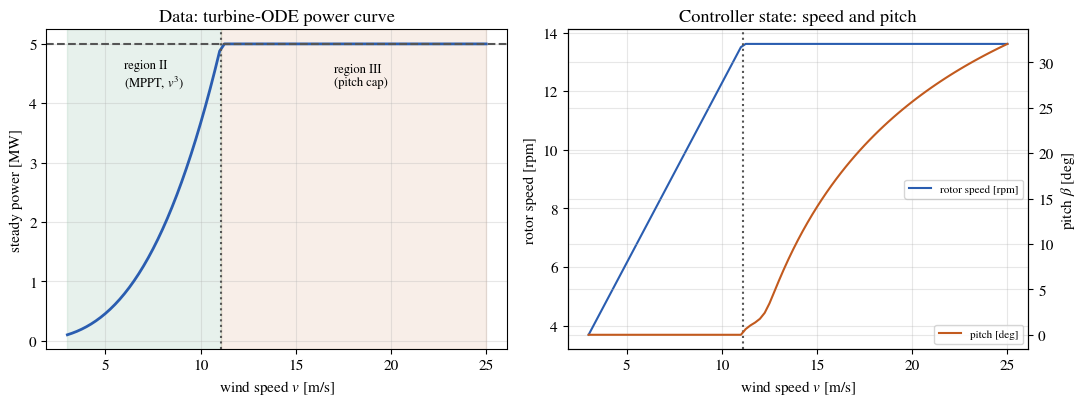

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.nets import MLP
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.benchmarks import turbine
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

# --- ground truth: steady power curve from the turbine rotor ODE + controller ---
p = turbine.TurbineParams(); V_RATED = p.v_rated
vv = np.linspace(p.v_in, p.v_out, 89)
P, OM, BE = turbine.power_curve(vv, p=p)
Pmw = P / 1e6; rpm = OM * 30.0 / np.pi
print(f'v_rated={V_RATED:.2f} m/s   rated power={p.P_rated/1e6:.1f} MW')

# show the data: power curve + the controller's two regions
def plot_ddm_wind_sweep():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].axvspan(p.v_in, V_RATED, color='C2', alpha=0.10)
    ax[0].axvspan(V_RATED, p.v_out, color='C1', alpha=0.10)
    ax[0].plot(vv, Pmw, 'C0', lw=2)
    ax[0].axhline(p.P_rated/1e6, ls='--', color=muted())
    ax[0].axvline(V_RATED, ls=':', color=muted())
    ax[0].text(6.0, 4.3, 'region II\n(MPPT, $v^3$)', fontsize=9)
    ax[0].text(17.0, 4.3, 'region III\n(pitch cap)', fontsize=9)
    ax[0].set(xlabel='wind speed $v$ [m/s]', ylabel='steady power [MW]',
              title='Data: turbine-ODE power curve')
    ax[1].plot(vv, rpm, 'C0', label='rotor speed [rpm]')
    ax2 = ax[1].twinx(); ax2.plot(vv, BE, 'C1', label='pitch [deg]')
    ax[1].axvline(V_RATED, ls=':', color=muted())
    ax[1].set(xlabel='wind speed $v$ [m/s]', ylabel='rotor speed [rpm]',
              title='Controller state: speed and pitch')
    ax2.set_ylabel('pitch $\\beta$ [deg]')
    ax[1].legend(loc='center right', fontsize=8); ax2.legend(loc='lower right', fontsize=8)
    plt.tight_layout()

plot_ddm_wind_sweep(); plt.show()

The print reports **$v_\text{rated}=11.09$ m/s** and the $5.0$ MW rating. Left figure: power rises
cubically through the green region II and flattens exactly at $5$ MW across the orange region III.
Right figure: rotor speed (blue) climbs linearly to $\sim\!13.6$ rpm at rated then holds flat, while
pitch $\beta$ (orange) stays $0°$ in region II and ramps to $\sim\!32°$ across region III — the two
control actions that produce the cap. Leaves the truth arrays `vv`, `Pmw`, `rpm`, `BE` for the fit.

## Train in region II, extrapolate into region III

The split is **in wind speed**, and region III is never trained on. Of the 33 region-II speeds ($v<v_\text{rated}=11.09$ m/s), **25 train** the surrogate $\hat P_\theta(v)\approx P(v)$ (`MLP([1,32,32,1])`, input and target standardized on the training points, Adam `lr=3e-3`, up to 4000 steps, MSE loss), **4 form the validation set** that picks the stopping step, and **4 are the in-range test** for **interpolation**; the whole of region III ($v\ge v_\text{rated}$, 56 speeds) is the out-of-range test for **extrapolation** across the controller's regime change — a regime, and a pitch-capping action, the network never saw. The data card `ddm_wind_split` shows the four sets on the curve, with the pitch angle in grey.

points v -> P:  train=25  validation=4  test-in=4  test-out (region III)=56


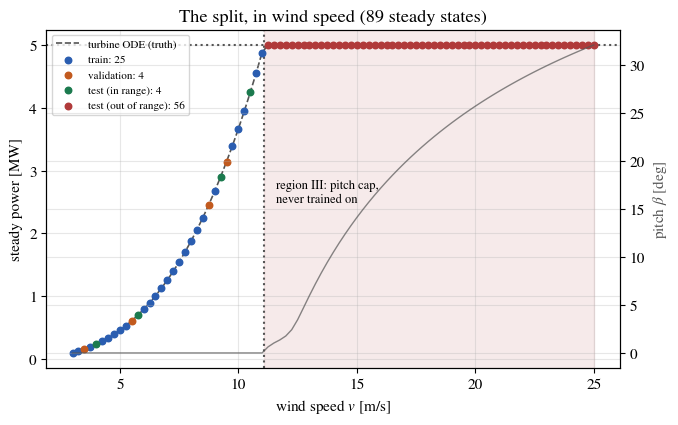

final train loss 2.43e-06   best validation loss 2.54e-07 at step 1950
RMSE  validation = 0.001 MW   test-in (held-out region II) = 0.003 MW   test-out (region III) = 3.646 MW
peak surrogate power in region III = 9.2 MW  (true cap = 5.0 MW)


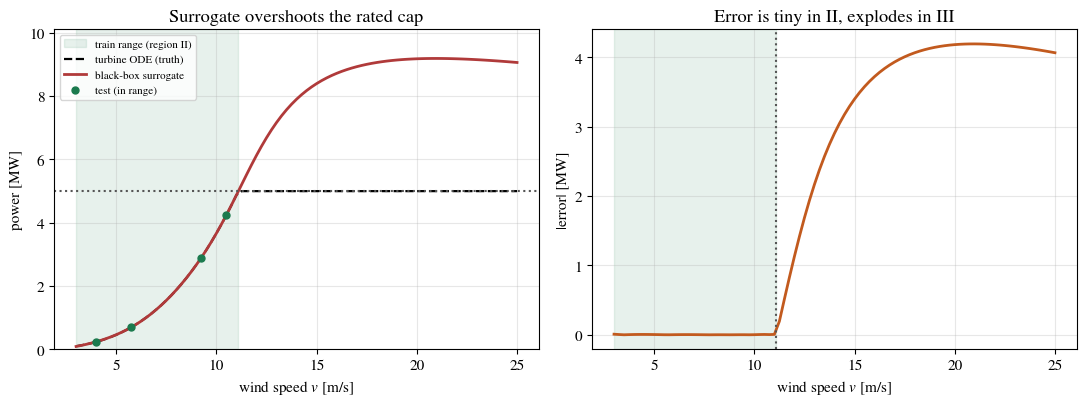

In [2]:
# --- the split, in wind speed: region II only; region III is never trained on ----
region_II = vv < V_RATED
rng = np.random.default_rng(0)
idx_II = rng.permutation(np.where(region_II)[0])
val_mask    = np.zeros_like(region_II); val_mask[idx_II[:4]] = True        # choose when to stop
interp_mask = np.zeros_like(region_II); interp_mask[idx_II[4:8]] = True    # test, in range
train_mask  = region_II & ~val_mask & ~interp_mask                          # fit
extrap_mask = ~region_II                                                    # test, out of range
print(f'points v -> P:  train={train_mask.sum()}  validation={val_mask.sum()}  test-in={interp_mask.sum()}  '
      f'test-out (region III)={extrap_mask.sum()}')

def plot_ddm_wind_split():
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    ax.axvspan(V_RATED, p.v_out, color='C3', alpha=0.10)
    ax.plot(vv, Pmw, '--', color=muted(), lw=1.2, label='turbine ODE (truth)')
    for m, c, tag in [(train_mask, 'C0', 'train'), (val_mask, 'C1', 'validation'),
                      (interp_mask, 'C2', 'test (in range)'), (extrap_mask, 'C3', 'test (out of range)')]:
        ax.scatter(vv[m], Pmw[m], s=22, color=c, zorder=3, label=f'{tag}: {m.sum()}')
    ax.axvline(V_RATED, ls=':', color=muted()); ax.axhline(p.P_rated/1e6, ls=':', color=muted())
    ax.text(V_RATED + 0.5, 2.5, 'region III: pitch cap,\nnever trained on', fontsize=9)
    ax2 = ax.twinx(); ax2.plot(vv, BE, color=muted(), lw=1, alpha=0.7); ax2.set_ylabel('pitch $\\beta$ [deg]', color=muted())
    ax.set(xlabel='wind speed $v$ [m/s]', ylabel='steady power [MW]', title='The split, in wind speed (89 steady states)')
    ax.legend(fontsize=8, loc='upper left')

save_dual(plot_ddm_wind_split, 'ddm_wind_split', FIG); plt.show()

vm, vs = vv[train_mask].mean(), vv[train_mask].std()
pm, ps = Pmw[train_mask].mean(), Pmw[train_mask].std()
def to_x(v): return torch.tensor(((np.atleast_1d(v) - vm) / vs).reshape(-1, 1))
def to_y(P): return torch.tensor(((np.atleast_1d(P) - pm) / ps).reshape(-1, 1))
Xt, Yt = to_x(vv[train_mask]), to_y(Pmw[train_mask]); Xv, Yv = to_x(vv[val_mask]), to_y(Pmw[val_mask])

torch.manual_seed(0); net = MLP([1, 32, 32, 1]); opt = torch.optim.Adam(net.parameters(), lr=3e-3)
best, best_step, best_state = np.inf, 0, None
for step in range(1, 4001):                                     # keep the best-validation parameters
    opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
    if step % 50 == 0:
        with torch.no_grad(): lva = float(((net(Xv) - Yv)**2).mean())
        if lva < best: best, best_step, best_state = lva, step, {k: v.clone() for k, v in net.state_dict().items()}
net.load_state_dict(best_state)
print(f'final train loss {float(loss.detach()):.2e}   best validation loss {best:.2e} at step {best_step}')

def predict(v):
    with torch.no_grad():
        return net(to_x(v)).numpy().ravel() * ps + pm
Pred = predict(vv)

rmse = lambda m: float(np.sqrt(np.mean((Pred[m] - Pmw[m])**2)))
e_val, e_interp, e_extrap = rmse(val_mask), rmse(interp_mask), rmse(extrap_mask)
overshoot = Pred[extrap_mask].max()
print(f'RMSE  validation = {e_val:.3f} MW   test-in (held-out region II) = {e_interp:.3f} MW   '
      f'test-out (region III) = {e_extrap:.3f} MW')
print(f'peak surrogate power in region III = {overshoot:.1f} MW  (true cap = {p.P_rated/1e6:.1f} MW)')

def plot_ddm_wind_cliff():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].axvspan(p.v_in, V_RATED, color='C2', alpha=0.10, label='train range (region II)')
    ax[0].plot(vv, Pmw, '--', color=fg(), lw=1.6, label='turbine ODE (truth)')
    ax[0].plot(vv, Pred, 'C3', lw=2, label='black-box surrogate')
    ax[0].scatter(vv[interp_mask], Pmw[interp_mask], color='C2', zorder=5, s=25, label='test (in range)')
    ax[0].axhline(p.P_rated/1e6, ls=':', color=muted())
    ax[0].set(xlabel='wind speed $v$ [m/s]', ylabel='power [MW]',
              title='Surrogate overshoots the rated cap', ylim=(0, 1.1*overshoot))
    ax[0].legend(fontsize=8, loc='upper left')
    ax[1].axvspan(p.v_in, V_RATED, color='C2', alpha=0.10)
    ax[1].plot(vv, np.abs(Pred - Pmw), 'C1', lw=2)
    ax[1].axvline(V_RATED, ls=':', color=muted())
    ax[1].set(xlabel='wind speed $v$ [m/s]', ylabel='|error| [MW]',
              title='Error is tiny in II, explodes in III')
    plt.tight_layout()

save_dual(plot_ddm_wind_cliff, 'ddm_wind_cliff', FIG); plt.show()
assert e_extrap > 5 * e_interp        # extrapolation error dwarfs interpolation
assert overshoot > 1.4 * p.P_rated/1e6  # surrogate blows past the physical cap

Validation stops the run at step 1950, and the in-range numbers agree: **validation RMSE 0.001 MW, in-range test RMSE 0.003 MW**. Then, never having seen the pitch cap, the surrogate **extrapolates the cubic rise straight past $5$ MW**, peaking at **9.2 MW** near $v\approx20$ m/s against the true $5.0$ MW cap. The **out-of-range RMSE is $3.65$ MW**, roughly $1200\times$ the in-range error; the right panel is flat at zero in region II and climbs to $\sim\!4.2$ MW in region III. Both asserts (out-of-range $>5\times$ in-range; overshoot $>1.4\times$ rated) pass. The failure is a missing *mechanism* — the pitch controller — not missing data.

**Lesson.** In region II the surrogate is excellent, and inference is a single forward pass ---
far cheaper than integrating the rotor ODE. But it has no knowledge of the pitch controller that
caps power in region III, so it extrapolates the cubic rise straight past the rated limit,
predicting power the machine will never (and must never) produce. No amount of region-II data fixes
this: the failure is a missing *mechanism*, not missing data. A regime the data never shows is a
regime the model cannot know.